Imports and setup

In [16]:
# Cell 1 — imports and setup
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

os.makedirs("figures", exist_ok=True)   # folder for saved plots
pd.set_option("display.width", 120)
print("Ready!")

Ready!


Generate synthetic data

In [17]:
# Cell 2 — synthetic data generator (same format as the app export)

# The "true" effects we build into the fake data. The analysis should find these.
TRUE_EFFECTS = {
    "ent_h_wc":       -0.25,  # same day: +1 h social/video above own average -> mood -0.25
    "ent_h_wc_lag":   -0.15,  # yesterday's extra social/video hour -> mood -0.15 today
    "mood_wc_lag":     0.30,  # a good day tends to be followed by a good day
    "sleep_hours_wc":  0.30,  # +1 h sleep -> mood +0.30
    "weekend":         0.30,  # weekends slightly better
    "ent_h_pm":        0.20,  # BETWEEN people: heavier users are slightly happier on average
}

def generate_synthetic(n_participants=20, n_days=60, missing_rate=0.15, seed=42):
    rng = np.random.default_rng(seed)          # seed = same "random" data every time
    dates = pd.date_range("2026-01-05", periods=n_days, freq="D")
    mood_rows, usage_rows = [], []
    checkin_id = 1

    for p in range(1, n_participants + 1):
        pid = f"SYN-{p:02d}"
        # Each person has their own typical usage and typical mood
        base_social = rng.gamma(4, 20)          # typical social minutes/day
        base_video = rng.gamma(3, 15)           # typical video minutes/day
        base_ent_h = (base_social + base_video) / 60
        base_mood = rng.normal(4.3, 0.4) + TRUE_EFFECTS["ent_h_pm"] * (base_ent_h - 2.0)
        prev_mood_dev, prev_ent_dev = 0.0, 0.0

        for date in dates:
            weekend = date.dayofweek >= 5
            social = max(0.0, rng.normal(base_social + (30 if weekend else 0), 25))
            video = max(0.0, rng.normal(base_video + (20 if weekend else 0), 20))
            messaging = max(0.0, rng.normal(50, 15))
            productivity = max(0.0, rng.normal(25 if weekend else 45, 15))
            other = max(0.0, rng.normal(15, 5))
            sleep = float(np.clip(np.round(rng.normal(7, 1) * 2) / 2, 3.5, 10))

            # Today's mood is built from the true effects + random noise
            ent_dev = (social + video) / 60 - base_ent_h
            mood_latent = (base_mood
                           + TRUE_EFFECTS["ent_h_wc"] * ent_dev
                           + TRUE_EFFECTS["ent_h_wc_lag"] * prev_ent_dev
                           + TRUE_EFFECTS["mood_wc_lag"] * prev_mood_dev
                           + TRUE_EFFECTS["sleep_hours_wc"] * (sleep - 7)
                           + TRUE_EFFECTS["weekend"] * weekend
                           + rng.normal(0, 0.6))
            prev_mood_dev, prev_ent_dev = mood_latent - base_mood, ent_dev

            # Usage rows (like daily_usage.csv) — recorded every day
            date_str = date.strftime("%Y-%m-%d")
            for category, minutes in [("social", social), ("video", video),
                                      ("messaging", messaging),
                                      ("productivity", productivity), ("other", other)]:
                if round(minutes) >= 1:
                    usage_rows.append({"participant_id": pid, "date": date_str,
                                       "category": category, "minutes": int(round(minutes))})

            # Some days the participant forgets to check in
            if rng.random() < missing_rate:
                continue

            energy = 4 + 0.4 * (sleep - 7) + 0.4 * (mood_latent - base_mood) + rng.normal(0, 0.7)
            stress = 4 - 0.5 * (mood_latent - base_mood) + rng.normal(0, 0.8)
            checkin_time = date + pd.Timedelta(hours=21) + pd.Timedelta(minutes=float(rng.normal(0, 45)))

            # Check-in row (like mood_checkins.csv) — scores rounded to 1–7 like the app
            mood_rows.append({
                "participant_id": pid, "checkin_id": checkin_id,
                "timestamp_ms": int(checkin_time.timestamp() * 1000),
                "local_datetime": checkin_time.isoformat(), "date": date_str,
                "mood": int(np.clip(round(mood_latent), 1, 7)),
                "energy": int(np.clip(round(energy), 1, 7)),
                "stress": int(np.clip(round(stress), 1, 7)),
                "sleep_hours": sleep,
            })
            checkin_id += 1

    return pd.DataFrame(mood_rows), pd.DataFrame(usage_rows)

mood_raw, usage_raw = generate_synthetic()
print("Check-ins:", mood_raw.shape, " Usage rows:", usage_raw.shape)
mood_raw.head()

Check-ins: (1019, 9)  Usage rows: (5888, 4)


,participant_id,checkin_id,timestamp_ms,local_datetime,date,mood,energy,stress,sleep_hours
0,SYN-01,1,1767644479910,2026-01-05T20:21:19.910350216,2026-01-05,5,6,4,8.0
1,SYN-01,2,1767734637234,2026-01-06T21:23:57.234800994,2026-01-06,5,4,3,6.5
2,SYN-01,3,1767817331577,2026-01-07T20:22:11.577512202,2026-01-07,3,4,4,6.5
3,SYN-01,4,1767907833066,2026-01-08T21:30:33.066620294,2026-01-08,4,5,4,7.0
4,SYN-01,5,1768077551650,2026-01-10T20:39:11.650159806,2026-01-10,4,5,4,7.0


Clean and merge the data

In [18]:
# Cell 3 — cleaning functions (work on synthetic AND real exports)

CATEGORIES = ["social", "video", "messaging", "productivity", "browsing",
              "games", "music_audio", "news", "photos", "maps", "other"]

def prepare_daily(mood, usage):
    """One row per participant per day: mood averages + minutes per category."""
    mood, usage = mood.copy(), usage.copy()
    mood["date"] = pd.to_datetime(mood["date"])
    usage["date"] = pd.to_datetime(usage["date"])

    # Rule: several check-ins on one day -> use the mean
    daily_mood = (mood.groupby(["participant_id", "date"])
                  .agg(mood=("mood", "mean"), energy=("energy", "mean"),
                       stress=("stress", "mean"), sleep_hours=("sleep_hours", "mean"),
                       n_checkins=("mood", "size"))
                  .reset_index())

    # Categories become columns; a missing category that day = 0 minutes
    usage_wide = (usage.pivot_table(index=["participant_id", "date"], columns="category",
                                    values="minutes", aggfunc="sum", fill_value=0)
                  .reset_index())
    usage_wide.columns.name = None
    for cat in CATEGORIES:
        if cat not in usage_wide.columns:
            usage_wide[cat] = 0
    usage_wide["total_min"] = usage_wide[CATEGORIES].sum(axis=1)
    usage_wide["ent_min"] = usage_wide["social"] + usage_wide["video"]

    # Rule: keep only days that have BOTH a check-in and usage data
    daily = daily_mood.merge(usage_wide, on=["participant_id", "date"], how="inner")
    daily["ent_h"] = daily["ent_min"] / 60          # social + video, in hours
    daily["total_h"] = daily["total_min"] / 60
    daily["weekend"] = (daily["date"].dt.dayofweek >= 5).astype(int)
    return daily.sort_values(["participant_id", "date"]).reset_index(drop=True)

def add_within_between(df, cols):
    """_pm = the person's average; _wc = today's difference from that average."""
    df = df.copy()
    for col in cols:
        person_mean = df.groupby("participant_id")[col].transform("mean")
        df[col + "_pm"] = person_mean
        df[col + "_wc"] = df[col] - person_mean
    return df

def add_lags(df, cols):
    """Yesterday's value — only if yesterday is exactly one day earlier."""
    df = df.sort_values(["participant_id", "date"]).copy()
    groups = df.groupby("participant_id")
    yesterday = groups["date"].shift(1)
    consecutive = (df["date"] - yesterday) == pd.Timedelta(days=1)
    for col in cols:
        df[col + "_lag"] = groups[col].shift(1).where(consecutive)
    return df

In [19]:
# Cell 4 — apply the cleaning to the synthetic data
daily = prepare_daily(mood_raw, usage_raw)
daily = add_within_between(daily, ["mood", "ent_h", "total_h", "sleep_hours"])
daily = add_lags(daily, ["mood_wc", "ent_h_wc"])
print(daily.shape)
daily[["participant_id", "date", "mood", "ent_h", "ent_h_wc", "ent_h_wc_lag", "sleep_hours"]].head(8)

(1019, 33)


,participant_id,date,mood,ent_h,ent_h_wc,ent_h_wc_lag,sleep_hours
0,SYN-01,2026-01-05,5.0,1.950000,-0.615972,NaN,8.0
1,SYN-01,2026-01-06,5.0,2.283333,-0.282639,-0.615972,6.5
2,SYN-01,2026-01-07,3.0,2.750000,0.184028,-0.282639,6.5
3,SYN-01,2026-01-08,4.0,2.316667,-0.249306,0.184028,7.0
4,SYN-01,2026-01-10,4.0,3.616667,1.050694,NaN,7.0
5,SYN-01,2026-01-11,4.0,3.583333,1.017361,1.050694,7.5
6,SYN-01,2026-01-12,3.0,2.466667,-0.099306,1.017361,6.0
7,SYN-01,2026-01-13,2.0,2.683333,0.117361,-0.099306,5.5


Descriptive statistics and plots

In [20]:
# Cell 5 — summary table
summary = daily[["mood", "energy", "stress", "sleep_hours", "ent_h", "total_h"]].describe().round(2)
summary

,mood,energy,stress,sleep_hours,ent_h,total_h
count,1019.00,1019.00,1019.00,1019.00,1019.00,1019.00
mean,4.24,3.98,4.03,6.99,2.59,4.32
std,0.91,0.94,0.93,0.99,0.98,0.98
min,2.00,1.00,1.00,3.50,0.23,1.53
25%,4.00,3.00,3.00,6.50,1.92,3.65
50%,4.00,4.00,4.00,7.00,2.47,4.23
75%,5.00,5.00,5.00,7.50,3.13,4.85
max,7.00,7.00,7.00,10.00,6.48,7.92


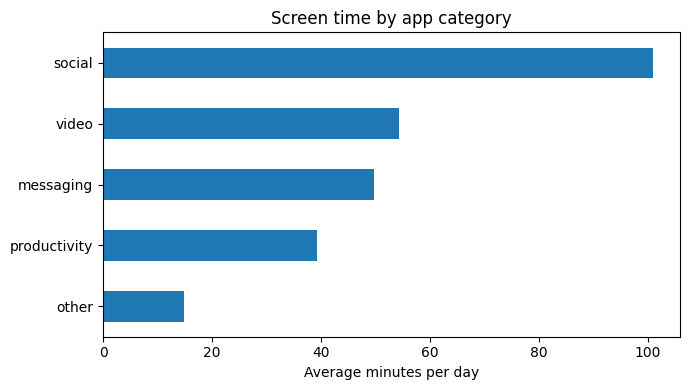

In [21]:
# Cell 6 — average minutes per category
avg_minutes = daily[CATEGORIES].mean().sort_values()
avg_minutes = avg_minutes[avg_minutes > 0]
ax = avg_minutes.plot.barh(figsize=(7, 4), color="tab:blue")
ax.set_xlabel("Average minutes per day")
ax.set_title("Screen time by app category")
plt.tight_layout()
plt.savefig("figures/category_minutes.png", dpi=150)
plt.show()

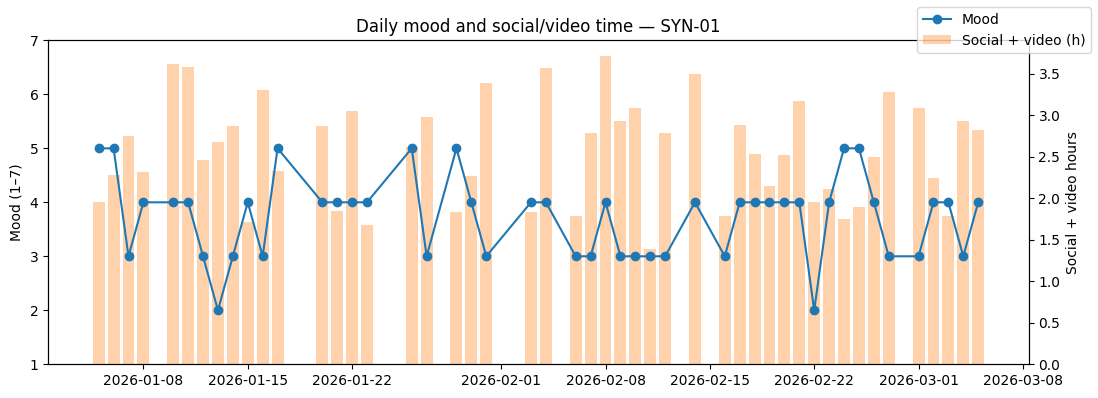

In [22]:
# Cell 7 — timeline for one person (reusable function)
def plot_timeline(df, participant, filename):
    one = df[df["participant_id"] == participant]
    fig, ax1 = plt.subplots(figsize=(11, 4))
    ax2 = ax1.twinx()   # second y-axis on the right
    ax2.bar(one["date"], one["ent_h"], color="tab:orange", alpha=0.35, label="Social + video (h)")
    ax1.plot(one["date"], one["mood"], marker="o", color="tab:blue", label="Mood")
    ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)  # line in front of bars
    ax1.set_ylabel("Mood (1–7)"); ax1.set_ylim(1, 7)
    ax2.set_ylabel("Social + video hours")
    ax1.set_title(f"Daily mood and social/video time — {participant}")
    fig.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig(f"figures/{filename}", dpi=150)
    plt.show()

plot_timeline(daily, "SYN-01", "timeline_synthetic.png")

Within-person vs between-person

Between-person r = 0.40  (n = 20 people)
Within-person  r = -0.07  (n = 1019 days; p-values here are approximate)


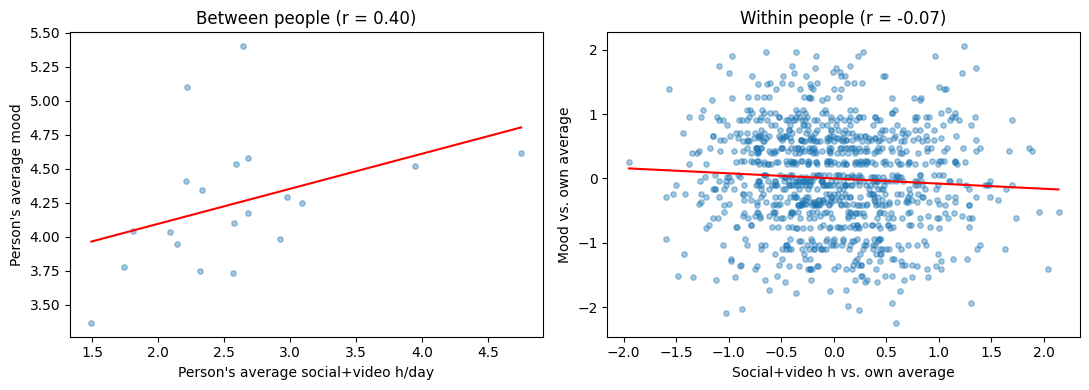

In [23]:
# Cell 8 — the two levels of analysis
person_means = daily.groupby("participant_id")[["ent_h", "mood"]].mean()
between_r, between_p = stats.pearsonr(person_means["ent_h"], person_means["mood"])
within_r, within_p = stats.pearsonr(daily["ent_h_wc"], daily["mood_wc"])

print(f"Between-person r = {between_r:.2f}  (n = {len(person_means)} people)")
print(f"Within-person  r = {within_r:.2f}  (n = {len(daily)} days; p-values here are approximate)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
panels = [
    (axes[0], person_means["ent_h"], person_means["mood"],
     f"Between people (r = {between_r:.2f})",
     "Person's average social+video h/day", "Person's average mood"),
    (axes[1], daily["ent_h_wc"], daily["mood_wc"],
     f"Within people (r = {within_r:.2f})",
     "Social+video h vs. own average", "Mood vs. own average"),
]
for ax, x, y, title, xlabel, ylabel in panels:
    ax.scatter(x, y, alpha=0.4, s=15)
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, intercept + slope * xs, color="red")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
plt.tight_layout()
plt.savefig("figures/within_vs_between.png", dpi=150)
plt.show()

Mixed-effects model and parameter recovery

In [24]:
# Cell 9 — mixed-effects model: what predicts today's mood?
model_data = daily.dropna(subset=["ent_h_wc_lag", "mood_wc_lag"])

mood_model = smf.mixedlm(
    "mood ~ ent_h_wc + ent_h_wc_lag + mood_wc_lag + sleep_hours_wc + weekend + ent_h_pm",
    data=model_data,
    groups=model_data["participant_id"],   # random intercept per person
).fit()
print(mood_model.summary())

          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: mood     
No. Observations:   855     Method:             REML     
No. Groups:         20      Scale:              0.4619   
Min. group size:    36      Log-Likelihood:     -923.1867
Max. group size:    52      Converged:          Yes      
Mean group size:    42.8                                 
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       3.474    0.374  9.281 0.000  2.740  4.208
ent_h_wc       -0.195    0.044 -4.475 0.000 -0.280 -0.110
ent_h_wc_lag   -0.208    0.037 -5.669 0.000 -0.280 -0.136
mood_wc_lag     0.253    0.029  8.623 0.000  0.195  0.310
sleep_hours_wc  0.303    0.024 12.490 0.000  0.256  0.351
weekend         0.330    0.063  5.226 0.000  0.206  0.454
ent_h_pm        0.259    0.139  1.863 0.062 -0.013  0.532
Group Var       0.191   

In [25]:
# Cell 10 — did the model recover the true effects?
ci = mood_model.conf_int()
recovery = pd.DataFrame({
    "true value": pd.Series(TRUE_EFFECTS),
    "estimated": mood_model.params,
    "95% CI low": ci[0],
    "95% CI high": ci[1],
}).dropna(subset=["true value"]).round(3)
recovery["true value inside CI?"] = recovery["true value"].between(
    recovery["95% CI low"], recovery["95% CI high"])
recovery

,true value,estimated,95% CI low,95% CI high,true value inside CI?
ent_h_pm,0.20,0.259,-0.013,0.532,True
ent_h_wc,-0.25,-0.195,-0.280,-0.110,True
ent_h_wc_lag,-0.15,-0.208,-0.280,-0.136,True
mood_wc_lag,0.30,0.253,0.195,0.310,True
sleep_hours_wc,0.30,0.303,0.256,0.351,True
weekend,0.30,0.330,0.206,0.454,True


The reverse direction

In [26]:
# Cell 11 — does yesterday's mood predict today's social/video time?
reverse_model = smf.mixedlm(
    "ent_h_wc ~ mood_wc_lag + ent_h_wc_lag + weekend",
    data=model_data,
    groups=model_data["participant_id"],
).fit()
print(reverse_model.summary())

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: ent_h_wc 
No. Observations: 855     Method:             REML     
No. Groups:       20      Scale:              0.2872   
Min. group size:  36      Log-Likelihood:     -688.7189
Max. group size:  52      Converged:          Yes      
Mean group size:  42.8                                 
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept    -0.202    0.022 -9.344 0.000 -0.244 -0.159
mood_wc_lag   0.040    0.023  1.751 0.080 -0.005  0.085
ent_h_wc_lag  0.023    0.029  0.800 0.424 -0.033  0.080
weekend       0.782    0.042 18.697 0.000  0.700  0.864
Group Var     0.000                                    



/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is si

Your real pilot data

Download the figures.

In [27]:
# Cell 12 — download all figures as one zip
from google.colab import files
!zip -r figures.zip figures
files.download("figures.zip")

updating: figures/ (stored 0%)
updating: figures/within_vs_between.png (deflated 6%)
updating: figures/timeline_synthetic.png (deflated 8%)
updating: figures/category_minutes.png (deflated 23%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Pilot data
Real data (n = 1, ~1 week) was collected with the app and exported successfully,
but it is not analysed in this version. Applying this pipeline to real
participant data is planned as future work.